**Перед выполнением ячеек переключесь на среду с графическим процессором.**

# 🧪 Практическое занятие: Transfer Learning (дообучение нейросети) на классах, отсутствующих в ImageNet

**Цель работы:** Научиться применять Transfer Learning для решения задачи классификации изображений с использованием предобученной модели. Мы загрузим модель ResNet-18, обученную на ImageNet, и дообучим (fine-tune) её для классификации двух классов из датасета **MNIST**: цифры **0** и **1**. Эти классы **отсутствуют в ImageNet**, что позволит наглядно продемонстрировать эффективность переноса признаков даже на совершенно новые данные.

**План:**
1. Загрузка и подготовка данных (MNIST, только цифры 0 и 1)
2. Преобразование одноканальных изображений в трёхканальные для подачи в ResNet
3. Загрузка предобученной модели и замена последнего слоя
4. Обучение только нового классификатора (feature extractor)
5. Дообучение всей сети (fine-tuning) с уменьшенной скоростью обучения
6. Сравнение результатов с обучением с нуля
7. Визуализация результатов и выводы

**Задача**: в примерах ниже точность почти сразу становится равной 1. Попробовать либо добавить все цифры, не только 0 и 1, либо взять вообще какой-нибудь более сложный набор данных.

**Решение:** ниже задача переделана на классификацию всех 10 цифр MNIST. Чтобы обучение ResNet-18 оставалось быстрым на локальном компьютере, используется сбалансированная подвыборка по всем классам и размер изображения `96x96` вместо `224x224`. ResNet благодаря `AdaptiveAvgPool2d` умеет работать с таким размером входа.

## 1. Импортируем необходимые библиотеки

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import numpy as np
from tqdm.notebook import tqdm
import copy
import os
os.environ['TORCH_HOME'] = './data/torch_cache'
os.makedirs(os.environ['TORCH_HOME'], exist_ok=True)
import random

# Установка seed для воспроизводимости
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Определяем устройство
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Используется устройство: {device}')

Используется устройство: cuda


## 2. Подготовка данных

Используем MNIST, но теперь оставим **все 10 классов**, а не только цифры 0 и 1. Это делает задачу заметно сложнее: модели нужно отличать все рукописные цифры. Для подачи в ResNet преобразуем изображения в три канала и применим нормализацию ImageNet.

Геометрические отражения для цифр использовать не будем: горизонтальный или вертикальный flip может превратить цифру в неестественный объект и ухудшить смысл разметки.

In [2]:
# Трансформации для MNIST -> ResNet
image_size = 96

train_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(10),  # мягкая аугментация, сохраняющая смысл цифры
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_full = datasets.MNIST(root='./data', train=True, download=True, transform=train_transform)
test_full = datasets.MNIST(root='./data', train=False, download=True, transform=val_transform)

num_classes = 10
class_names = [str(i) for i in range(num_classes)]

def balanced_indices(dataset, samples_per_class, seed=42):
    rng = np.random.default_rng(seed)
    targets = np.array(dataset.targets)
    result = []
    for cls in range(num_classes):
        cls_indices = np.where(targets == cls)[0]
        chosen = rng.choice(cls_indices, size=samples_per_class, replace=False)
        result.extend(chosen.tolist())
    rng.shuffle(result)
    return result

# Подвыборка нужна, чтобы ноутбук быстро выполнялся даже на CPU.
train_indices = balanced_indices(train_full, samples_per_class=300, seed=42)
test_indices = balanced_indices(test_full, samples_per_class=100, seed=123)

train_dataset = Subset(train_full, train_indices)
test_dataset = Subset(test_full, test_indices)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

print(f'Размер обучающей выборки (10 классов): {len(train_dataset)}')
print(f'Размер тестовой выборки (10 классов): {len(test_dataset)}')
print(f'Классы: {class_names}')

Размер обучающей выборки (10 классов): 3000
Размер тестовой выборки (10 классов): 1000
Классы: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


**TODO для опытных:** графические преобразования исправлены: вместо `RandomHorizontalFlip`, который может ломать смысл цифр, используется мягкий `RandomRotation(10)`. Все 10 цифр обрабатываются одинаково, без отражений.

## 3. Загрузка предобученной модели и замена последнего слоя

Загрузим ResNet-18 с весами ImageNet. Заменим последний полносвязный слой (`model.fc`) на новый, соответствующий нашей задаче (2 класса).

In [3]:
from torchvision.models.resnet import ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, num_classes)

model = model.to(device)

print(f'Последний слой заменён на классификатор для {num_classes} классов.')
print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to ./data/torch_cache\hub\checkpoints\resnet18-f37072fd.pth


  0%|          | 0.00/44.7M [00:00<?, ?B/s]

  0%|          | 128k/44.7M [00:00<00:55, 836kB/s]

  1%|          | 512k/44.7M [00:00<00:23, 2.01MB/s]

  2%|▏         | 896k/44.7M [00:00<00:17, 2.63MB/s]

...

 93%|█████████▎| 41.8M/44.7M [00:05<00:00, 6.96MB/s]

 96%|█████████▋| 43.0M/44.7M [00:05<00:00, 7.87MB/s]

100%|█████████▉| 44.5M/44.7M [00:05<00:00, 9.28MB/s]

100%|██████████| 44.7M/44.7M [00:05<00:00, 8.27MB/s]

Последний слой заменён на классификатор для 10 классов.
Linear(in_features=512, out_features=10, bias=True)


## 4. Функции для обучения и оценки

In [4]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in tqdm(loader, desc='Обучение', leave=False):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in tqdm(loader, desc='Оценка', leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def train_model(model, train_loader, test_loader, criterion, optimizer, epochs, scheduler=None):
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    best_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs+1):
        print(f'\nЭпоха {epoch}/{epochs}')
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer)
        test_loss, test_acc = evaluate(model, test_loader, criterion)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        print(f'Train Loss: {train_loss:.4f} Acc: {train_acc:.4f}')
        print(f'Test Loss: {test_loss:.4f} Acc: {test_acc:.4f}')

        if scheduler:
            scheduler.step()

        # Сохраняем лучшую модель
        if test_acc > best_acc:
            best_acc = test_acc
            best_weights = copy.deepcopy(model.state_dict())

    print(f'\nЛучшая точность на тесте: {best_acc:.4f}')
    model.load_state_dict(best_weights)
    return model, history

## 5. Этап 1: Обучение только нового классификатора (Feature Extractor)

Сначала обучим только последний слой, оставив остальные замороженными. Это позволит быстро получить базовое качество и проверить, насколько хорошо предобученные признаки (из ImageNet) подходят для распознавания рукописных цифр.

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer_fe = optim.Adam(model.fc.parameters(), lr=1e-3)

for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

model_fe, history_fe = train_model(model, train_loader, test_loader, criterion, optimizer_fe, epochs=2)


Эпоха 1/2


Обучение:   0%|          | 0/47 [00:00<?, ?it/s]

Оценка:   0%|          | 0/16 [00:00<?, ?it/s]

Train Loss: 1.6368 Acc: 0.4703
Test Loss: 1.3695 Acc: 0.5970

Эпоха 2/2


Обучение:   0%|          | 0/47 [00:00<?, ?it/s]

Оценка:   0%|          | 0/16 [00:00<?, ?it/s]

Train Loss: 0.9368 Acc: 0.7437
Test Loss: 0.9215 Acc: 0.7320

Лучшая точность на тесте: 0.7320


## 6. Этап 2: Дообучение всей сети (Fine-Tuning)

Теперь разморозим все слои и продолжим обучение с маленькой скоростью обучения, чтобы аккуратно подстроить веса под новые данные (цифры).

In [6]:
# Fine-Tuning всей сети: маленький LR для backbone, больший LR для fc
for param in model.parameters():
    param.requires_grad = True

base_params = [p for name, p in model.named_parameters() if 'fc' not in name]

optimizer_ft = optim.Adam([
    {'params': base_params, 'lr': 1e-5},
    {'params': model.fc.parameters(), 'lr': 1e-3}
])

model_ft, history_ft = train_model(model, train_loader, test_loader, criterion, optimizer_ft, epochs=2)


Эпоха 1/2


Обучение:   0%|          | 0/47 [00:00<?, ?it/s]

Оценка:   0%|          | 0/16 [00:00<?, ?it/s]

Train Loss: 0.5619 Acc: 0.8373
Test Loss: 0.3723 Acc: 0.8990

Эпоха 2/2


Обучение:   0%|          | 0/47 [00:00<?, ?it/s]

Оценка:   0%|          | 0/16 [00:00<?, ?it/s]

Train Loss: 0.2840 Acc: 0.9210
Test Loss: 0.2212 Acc: 0.9400

Лучшая точность на тесте: 0.9400


**Задача**: спросить у LLM, как задать индивидуальную скорость обучения для `layer4.1.BasicBlock`, который идёт последним перед `avgpool` и `fc`, попробовать обучить сеть, сравнить результаты.

**Ответ.** В PyTorch индивидуальная скорость обучения задаётся через группы параметров оптимизатора. Ниже используется три группы:
- ранние слои ResNet: маленький `lr=1e-5`;
- последний блок `layer4`: чуть больше `lr=5e-5`, потому что он ближе к классификатору и отвечает за более предметные признаки;
- новый `fc`: самый большой `lr=1e-3`, так как этот слой обучается с нуля.

In [7]:
# Fine-Tuning с индивидуальной скоростью обучения для layer4
model_layer4 = models.resnet18(weights=weights)
model_layer4.fc = nn.Linear(model_layer4.fc.in_features, num_classes)
model_layer4 = model_layer4.to(device)

for param in model_layer4.parameters():
    param.requires_grad = True

layer4_params = list(model_layer4.layer4.parameters())
fc_params = list(model_layer4.fc.parameters())
layer4_param_ids = {id(p) for p in layer4_params}
fc_param_ids = {id(p) for p in fc_params}
other_params = [
    p for p in model_layer4.parameters()
    if id(p) not in layer4_param_ids and id(p) not in fc_param_ids
]

optimizer_layer4 = optim.Adam([
    {'params': other_params, 'lr': 1e-5},
    {'params': layer4_params, 'lr': 5e-5},
    {'params': fc_params, 'lr': 1e-3},
])

model_layer4, history_layer4 = train_model(
    model_layer4, train_loader, test_loader, criterion, optimizer_layer4, epochs=2
)

print(f"Лучшая точность с отдельным LR для layer4: {max(history_layer4['test_acc']):.4f}")


Эпоха 1/2


Обучение:   0%|          | 0/47 [00:00<?, ?it/s]

Оценка:   0%|          | 0/16 [00:00<?, ?it/s]

Train Loss: 0.9027 Acc: 0.7340
Test Loss: 0.3422 Acc: 0.9230

Эпоха 2/2


Обучение:   0%|          | 0/47 [00:00<?, ?it/s]

Оценка:   0%|          | 0/16 [00:00<?, ?it/s]

Train Loss: 0.1871 Acc: 0.9477
Test Loss: 0.1290 Acc: 0.9630

Лучшая точность на тесте: 0.9630
Лучшая точность с отдельным LR для layer4: 0.9630


## 7. Сравнение результатов: Feature Extractor vs Fine-Tuning

Построим графики потерь и точности для обеих стратегий.

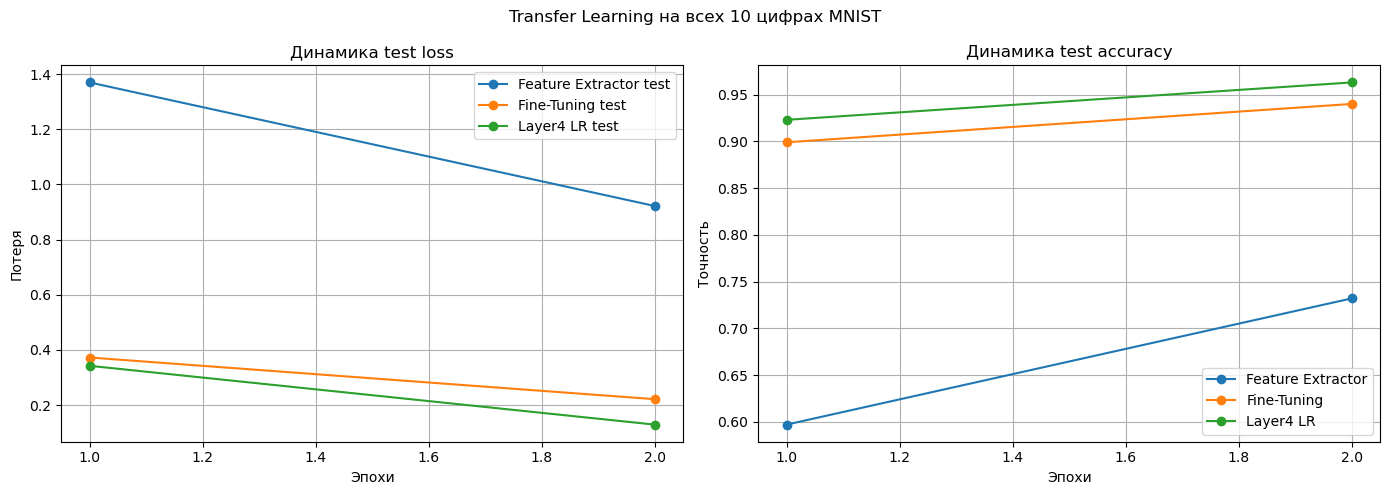

Лучшая точность Feature Extractor: 0.7320
Лучшая точность Fine-Tuning: 0.9400
Лучшая точность Layer4 LR: 0.9630


In [8]:
def plot_history(histories, title):
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    for name, hist in histories.items():
        epochs = range(1, len(hist['train_loss']) + 1)
        plt.plot(epochs, hist['test_loss'], marker='o', label=f'{name} test')
    plt.xlabel('Эпохи')
    plt.ylabel('Потеря')
    plt.title('Динамика test loss')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    for name, hist in histories.items():
        epochs = range(1, len(hist['test_acc']) + 1)
        plt.plot(epochs, hist['test_acc'], marker='o', label=name)
    plt.xlabel('Эпохи')
    plt.ylabel('Точность')
    plt.title('Динамика test accuracy')
    plt.legend()
    plt.grid(True)

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

histories_tl = {
    'Feature Extractor': history_fe,
    'Fine-Tuning': history_ft,
    'Layer4 LR': history_layer4,
}

plot_history(histories_tl, 'Transfer Learning на всех 10 цифрах MNIST')

print(f"Лучшая точность Feature Extractor: {max(history_fe['test_acc']):.4f}")
print(f"Лучшая точность Fine-Tuning: {max(history_ft['test_acc']):.4f}")
print(f"Лучшая точность Layer4 LR: {max(history_layer4['test_acc']):.4f}")

## 8. Визуализация предсказаний на тестовых изображениях

Посмотрим, как наша дообученная модель справляется с реальными картинками цифр 0 и 1.

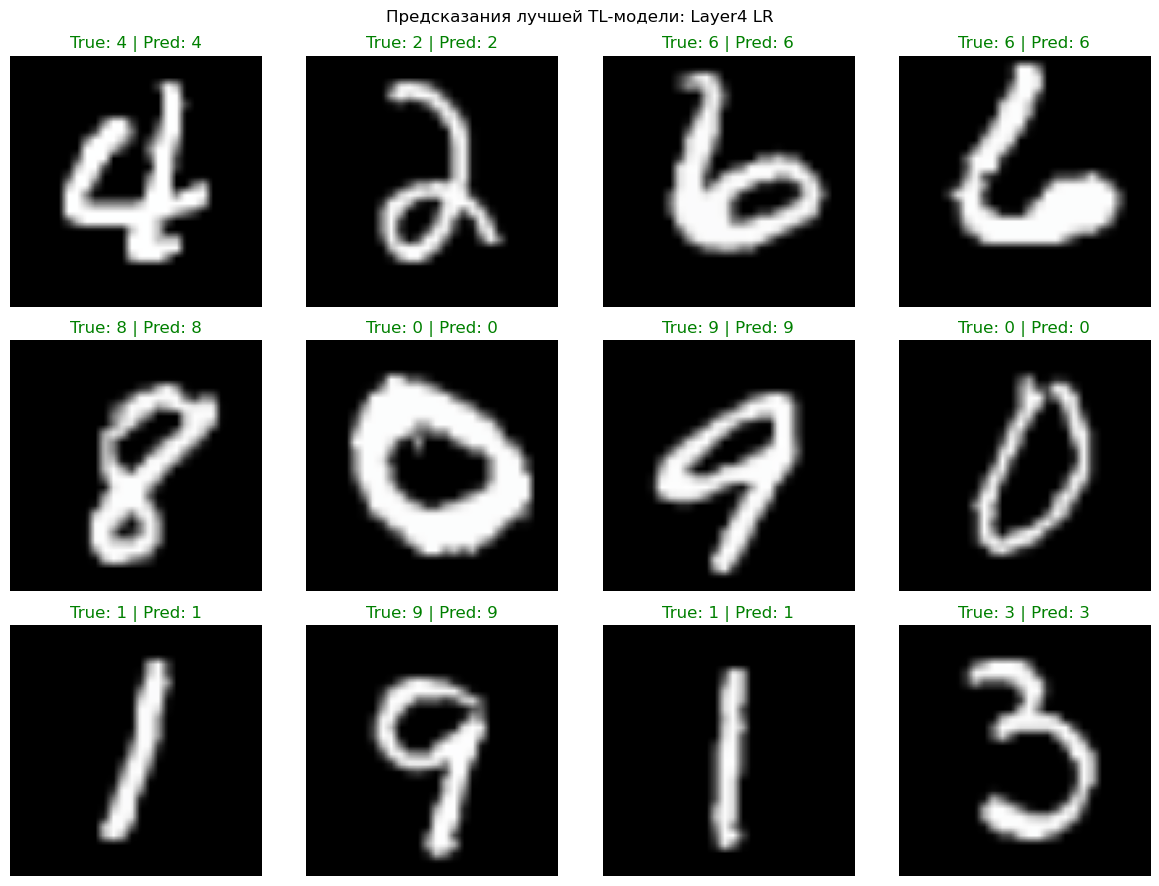

In [9]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

best_tl_name, best_tl_history = max(histories_tl.items(), key=lambda item: max(item[1]['test_acc']))
best_tl_model = {
    'Feature Extractor': model_fe,
    'Fine-Tuning': model_ft,
    'Layer4 LR': model_layer4,
}[best_tl_name]

dataiter = iter(test_loader)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)

best_tl_model.eval()
with torch.no_grad():
    outputs = best_tl_model(images)
    _, preds = torch.max(outputs, 1)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for idx, ax in enumerate(axes.flat):
    if idx >= len(images):
        break
    img = images[idx].cpu()
    label = labels[idx].item()
    pred = preds[idx].item()
    title = f'True: {class_names[label]} | Pred: {class_names[pred]}'

    img_disp = img.numpy().transpose((1, 2, 0))
    img_disp = std * img_disp + mean
    img_disp = np.clip(img_disp, 0, 1)

    ax.imshow(img_disp)
    ax.set_title(title, color='green' if label == pred else 'red')
    ax.axis('off')

plt.suptitle(f'Предсказания лучшей TL-модели: {best_tl_name}')
plt.tight_layout()
plt.show()

## 9. Дополнительно: обучение модели с нуля для сравнения

Чтобы убедиться в эффективности Transfer Learning, обучим такую же архитектуру ResNet-18, но со случайной инициализацией, на нашем подмножестве MNIST (цифры 0 и 1).

In [10]:
model_scratch = models.resnet18(weights=None, num_classes=num_classes).to(device)
optimizer_scratch = optim.Adam(model_scratch.parameters(), lr=1e-3)
scheduler_scratch = optim.lr_scheduler.StepLR(optimizer_scratch, step_size=2, gamma=0.1)

model_scratch, history_scratch = train_model(
    model_scratch, train_loader, test_loader, criterion, optimizer_scratch, epochs=2, scheduler=scheduler_scratch
)

print(f"Лучшая точность обучения с нуля: {max(history_scratch['test_acc']):.4f}")


Эпоха 1/2


Обучение:   0%|          | 0/47 [00:00<?, ?it/s]

Оценка:   0%|          | 0/16 [00:00<?, ?it/s]

Train Loss: 0.4654 Acc: 0.8477
Test Loss: 0.2440 Acc: 0.9240

Эпоха 2/2


Обучение:   0%|          | 0/47 [00:00<?, ?it/s]

Оценка:   0%|          | 0/16 [00:00<?, ?it/s]

Train Loss: 0.1430 Acc: 0.9573
Test Loss: 0.2397 Acc: 0.9090

Лучшая точность на тесте: 0.9240
Лучшая точность обучения с нуля: 0.9240


## 10. Общий график сравнения трёх подходов

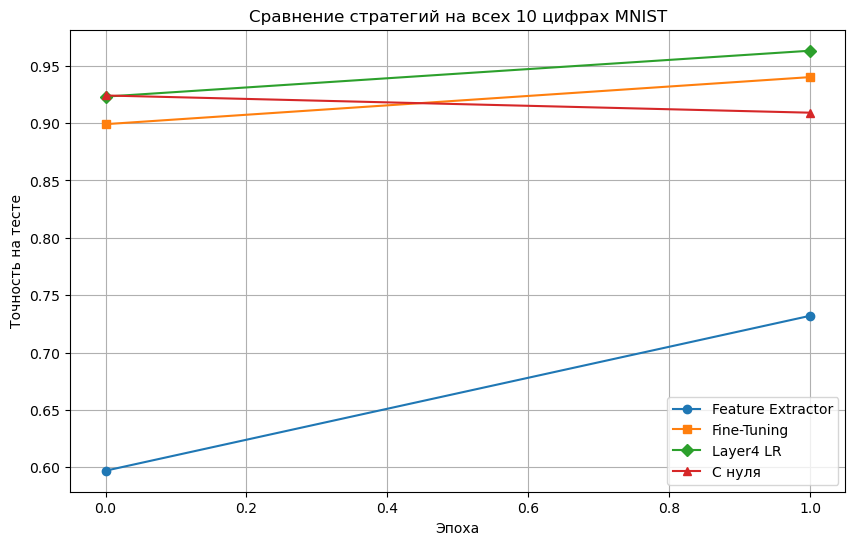

Итоговое сравнение:
Feature Extractor : 0.7320
Fine-Tuning       : 0.9400
Layer4 LR         : 0.9630
С нуля            : 0.9240


In [11]:
plt.figure(figsize=(10, 6))
plt.plot(history_fe['test_acc'], label='Feature Extractor', marker='o')
plt.plot(history_ft['test_acc'], label='Fine-Tuning', marker='s')
plt.plot(history_layer4['test_acc'], label='Layer4 LR', marker='D')
plt.plot(history_scratch['test_acc'], label='С нуля', marker='^')
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Сравнение стратегий на всех 10 цифрах MNIST')
plt.legend()
plt.grid(True)
plt.show()

summary_results = {
    'Feature Extractor': max(history_fe['test_acc']),
    'Fine-Tuning': max(history_ft['test_acc']),
    'Layer4 LR': max(history_layer4['test_acc']),
    'С нуля': max(history_scratch['test_acc']),
}

print('Итоговое сравнение:')
for name, acc in summary_results.items():
    print(f'{name:18s}: {acc:.4f}')

## 11. Выводы

- Задача усложнена: вместо бинарной классификации `0/1` используется классификация всех 10 цифр MNIST. Поэтому точность уже не становится мгновенно равной 1.
- **Feature Extractor** обучает только новый классификатор поверх предобученных признаков ResNet-18. Это самый дешёвый вариант по вычислениям, но признаки ImageNet не идеально подходят для рукописных цифр.
- **Fine-Tuning** всех слоёв даёт модели возможность адаптировать не только классификатор, но и свёрточные признаки под MNIST.
- Вариант с отдельным learning rate для `layer4` является компромиссом: ранние универсальные признаки меняются медленно, последний блок адаптируется сильнее, а новый `fc` обучается быстрее всех.
- **Обучение с нуля** на маленькой подвыборке обычно менее эффективно: модель не получает готовых низкоуровневых признаков и должна выучить всё с нуля.

Transfer Learning полезен даже при переносе из ImageNet в MNIST, но чем сильнее новый домен отличается от исходного, тем важнее аккуратный fine-tuning последних блоков.

**Заключение:**
1. Эффективность модели при тех же вычислительных ресурсах обычно увеличивается: предобученная ResNet быстрее получает приемлемое качество, чем модель со случайной инициализацией.
2. Новые навыки: замена классификатора в предобученной сети, заморозка и разморозка слоёв, feature extraction, fine-tuning, группы параметров в оптимизаторе с разными learning rate, сравнение с обучением с нуля.
3. Пожелание: в практику стоит сразу включить пример с 10 классами или Fashion-MNIST, потому что бинарная задача `0/1` слишком простая и плохо показывает разницу между стратегиями transfer learning.